<a href="https://colab.research.google.com/github/Athul-11/apexplanet-task-1/blob/main/randomforest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving data.csv to data.csv
Dataset loaded successfully!
File name: data.csv

First 5 rows:
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.

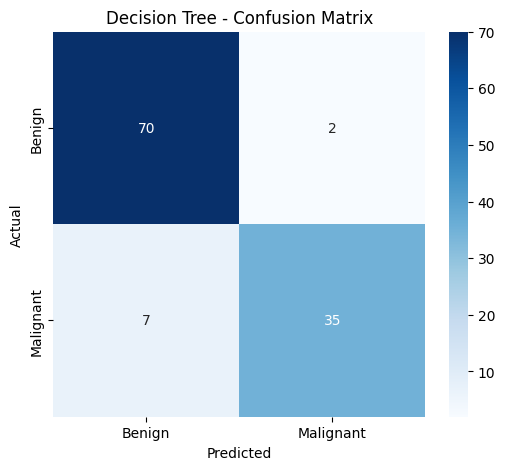

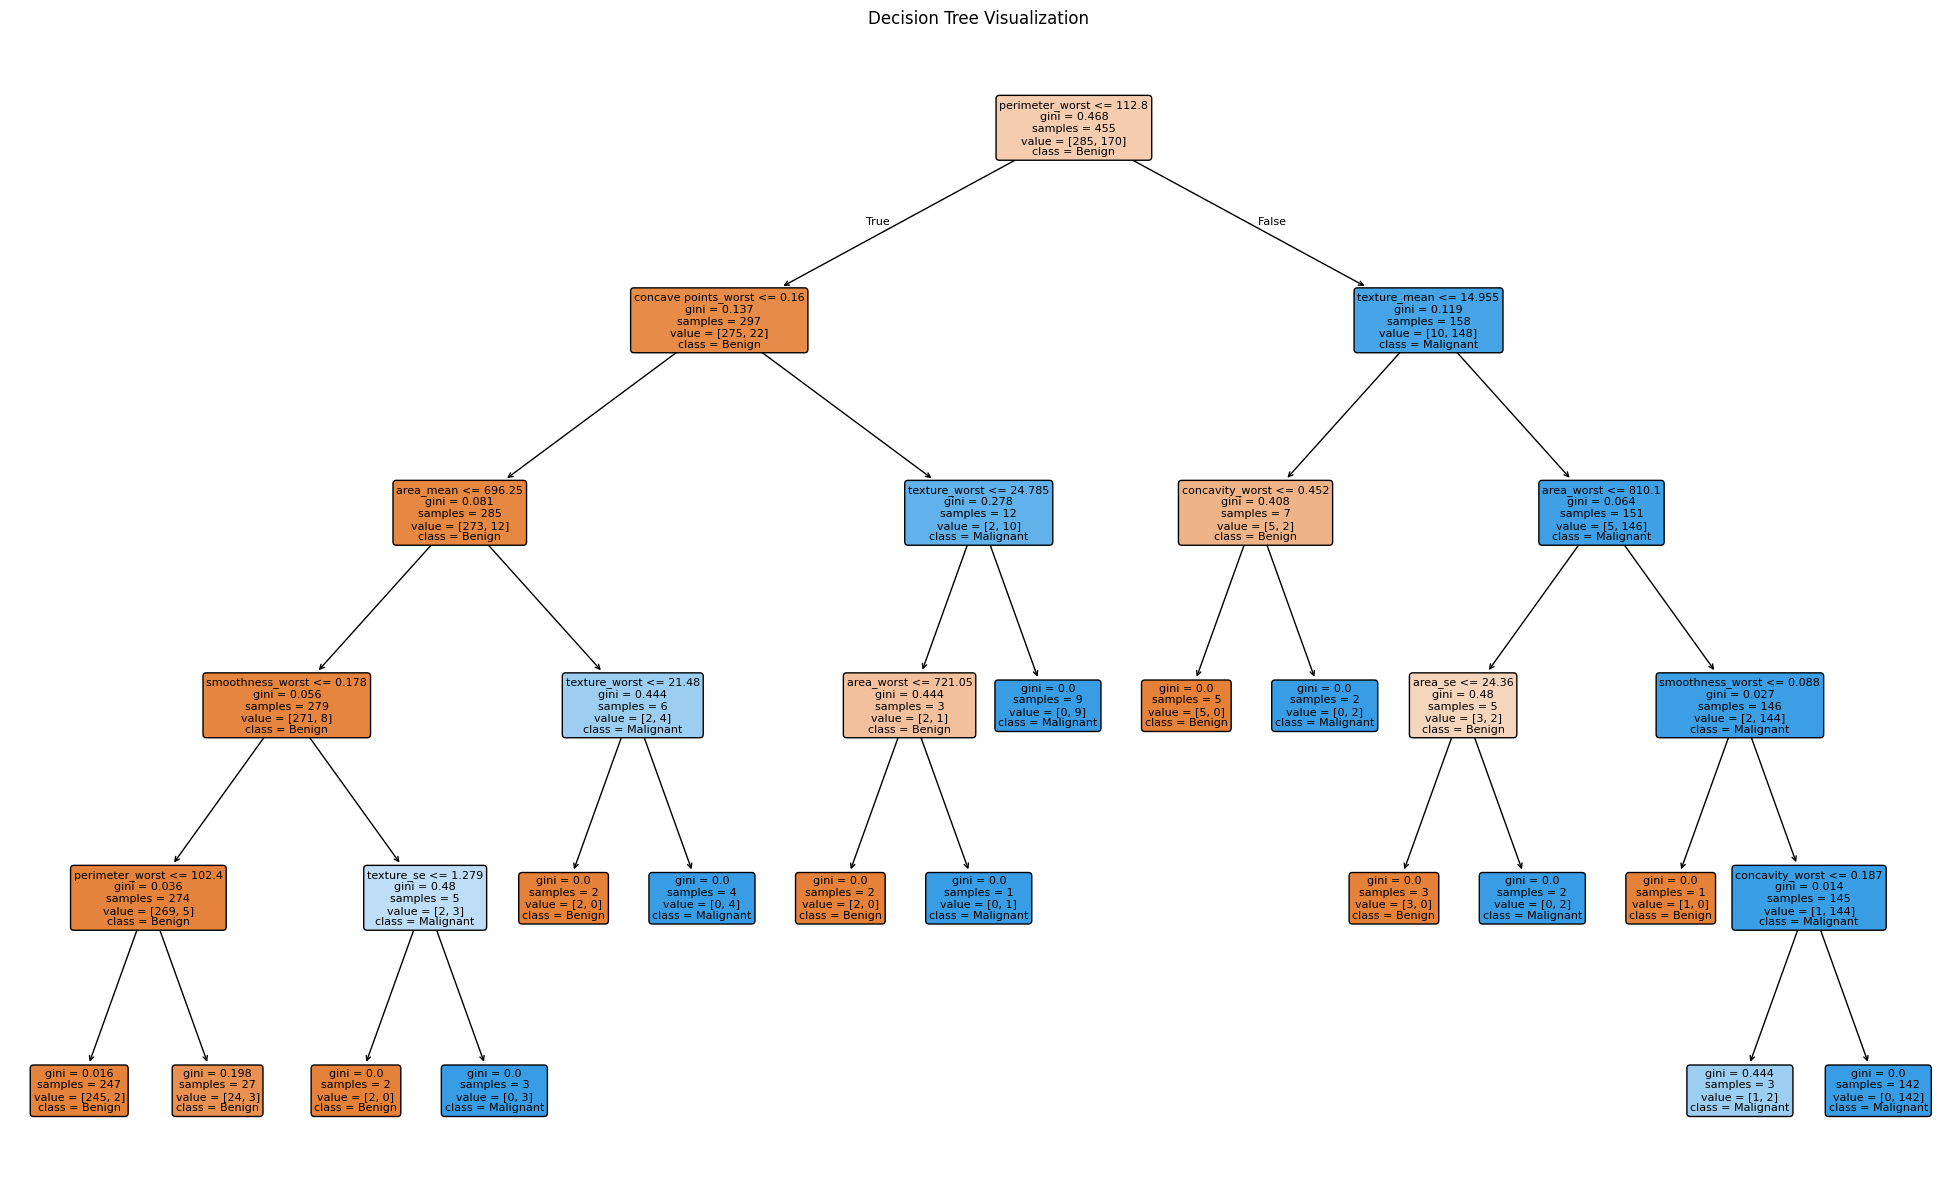


RANDOM FOREST
Random Forest Accuracy: 97.37 %

Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114


Confusion Matrix:
[[72  0]
 [ 3 39]]


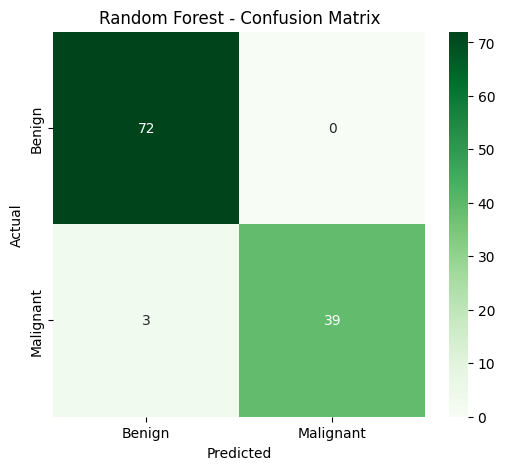


Top Important Features:
                 Feature  Importance
23            area_worst    0.151412
27  concave points_worst    0.126497
20          radius_worst    0.093475
22       perimeter_worst    0.083642
7    concave points_mean    0.081082
2         perimeter_mean    0.077126
0            radius_mean    0.061990
6         concavity_mean    0.050818
3              area_mean    0.045916
26       concavity_worst    0.030022


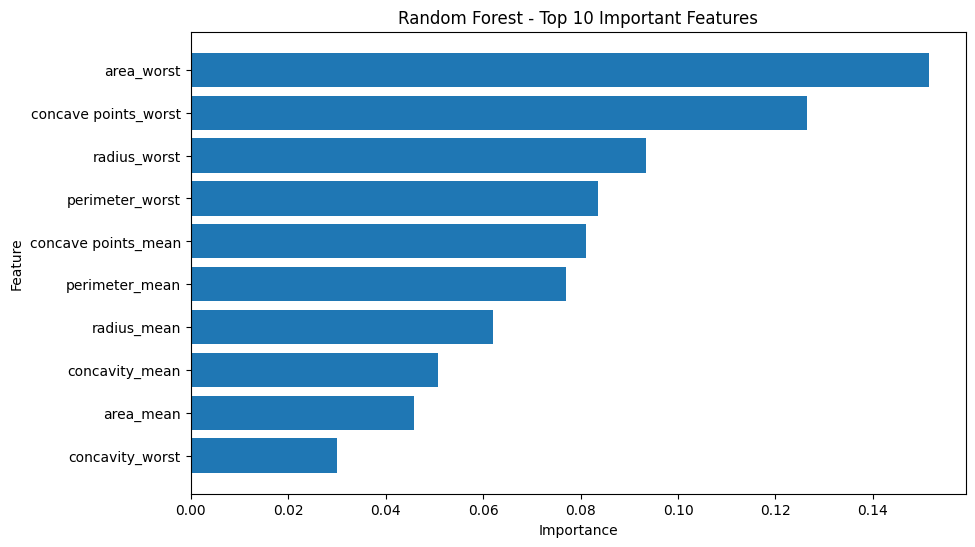


SUPPORT VECTOR MACHINE (SVM)
SVM Accuracy: 97.37 %

Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114


Confusion Matrix:
[[72  0]
 [ 3 39]]


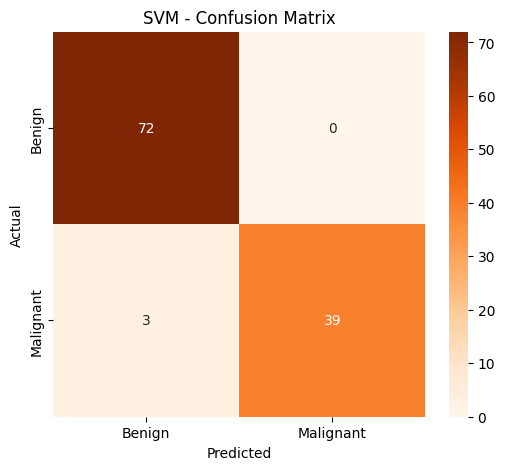


SVM DECISION BOUNDARY


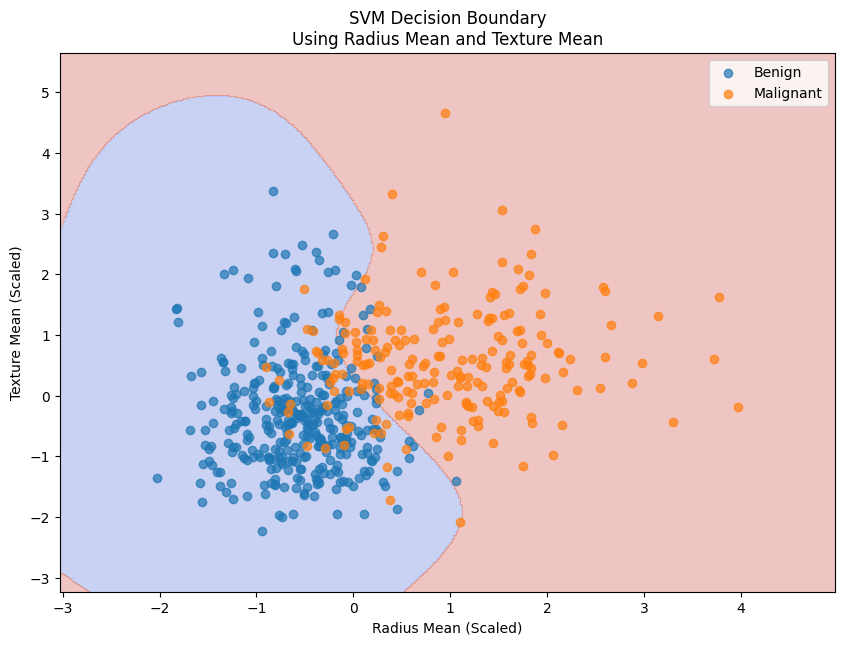


MODEL ACCURACY COMPARISON
Decision Tree : 92.11 %
Random Forest : 97.37 %
SVM           : 97.37 %


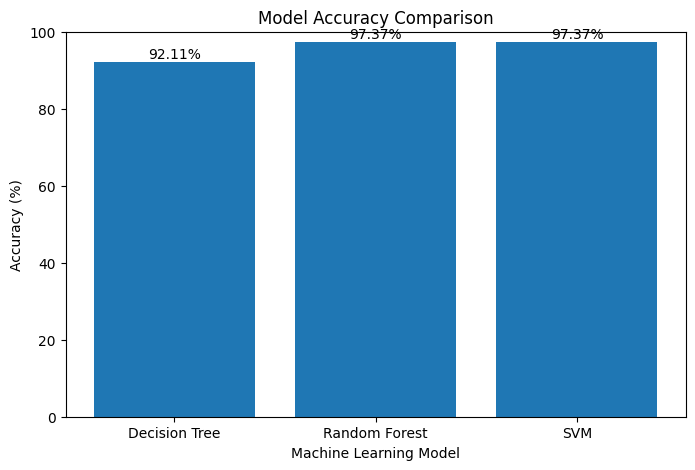


FINAL RESULTS
           Model  Accuracy (%)
0  Decision Tree         92.11
1  Random Forest         97.37
2            SVM         97.37


In [ ]:
# ============================================================
# BREAST CANCER CLASSIFICATION
# Decision Tree + Random Forest + SVM
# ============================================================

# STEP 1: Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)


# ============================================================
# STEP 2: Upload Kaggle dataset
# ============================================================

uploaded = files.upload()

file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("File name:", file_name)

print("\nFirst 5 rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns)


# ============================================================
# STEP 3: Remove unnecessary columns
# ============================================================

# Remove ID column
if 'id' in df.columns:
    df = df.drop('id', axis=1)

# Remove empty/unnamed column
if 'Unnamed: 32' in df.columns:
    df = df.drop('Unnamed: 32', axis=1)


# ============================================================
# STEP 4: Convert target column
# ============================================================

# M = Malignant
# B = Benign

df['diagnosis'] = df['diagnosis'].map({
    'M': 1,
    'B': 0
})

print("\nTarget values:")
print(df['diagnosis'].value_counts())


# ============================================================
# STEP 5: Separate input and output
# ============================================================

X = df.drop('diagnosis', axis=1)

y = df['diagnosis']

print("\nInput features:", X.shape)
print("Target:", y.shape)


# ============================================================
# STEP 6: Split dataset into training and testing
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining data:", X_train.shape)
print("Testing data:", X_test.shape)


# ============================================================
# STEP 7: Feature Scaling
# ============================================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)


# ============================================================
# MODEL 1: DECISION TREE
# ============================================================

print("\n====================================")
print("DECISION TREE")
print("====================================")

decision_tree = DecisionTreeClassifier(
    criterion='gini',
    max_depth=5,
    random_state=42
)

decision_tree.fit(X_train, y_train)

# Prediction
dt_pred = decision_tree.predict(X_test)

# Accuracy
dt_accuracy = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:",
      round(dt_accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    dt_pred,
    target_names=['Benign', 'Malignant']
))

# Confusion Matrix
dt_cm = confusion_matrix(y_test, dt_pred)

print("\nConfusion Matrix:")
print(dt_cm)


# ============================================================
# DECISION TREE CONFUSION MATRIX GRAPH
# ============================================================

plt.figure(figsize=(6, 5))

sns.heatmap(
    dt_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree - Confusion Matrix")

plt.show()


# ============================================================
# DECISION TREE VISUALIZATION
# ============================================================

plt.figure(figsize=(25, 15))

plot_tree(
    decision_tree,
    filled=True,
    rounded=True,
    feature_names=X.columns,
    class_names=['Benign', 'Malignant'],
    fontsize=8
)

plt.title("Decision Tree Visualization")

plt.show()


# ============================================================
# MODEL 2: RANDOM FOREST
# ============================================================

print("\n====================================")
print("RANDOM FOREST")
print("====================================")

random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_forest.fit(X_train, y_train)

# Prediction
rf_pred = random_forest.predict(X_test)

# Accuracy
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:",
      round(rf_accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")

print(classification_report(
    y_test,
    rf_pred,
    target_names=['Benign', 'Malignant']
))

# Confusion Matrix
rf_cm = confusion_matrix(y_test, rf_pred)

print("\nConfusion Matrix:")
print(rf_cm)


# ============================================================
# RANDOM FOREST CONFUSION MATRIX GRAPH
# ============================================================

plt.figure(figsize=(6, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest - Confusion Matrix")

plt.show()


# ============================================================
# RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

importance = random_forest.feature_importances_

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("\nTop Important Features:")
print(feature_importance.head(10))


# Plot feature importance

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance['Feature'].head(10)[::-1],
    feature_importance['Importance'].head(10)[::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest - Top 10 Important Features")

plt.show()


# ============================================================
# MODEL 3: SVM
# ============================================================

print("\n====================================")
print("SUPPORT VECTOR MACHINE (SVM)")
print("====================================")

svm_model = SVC(
    kernel='rbf',
    random_state=42
)

svm_model.fit(
    X_train_scaled,
    y_train
)

# Prediction
svm_pred = svm_model.predict(X_test_scaled)

# Accuracy
svm_accuracy = accuracy_score(
    y_test,
    svm_pred
)

print("SVM Accuracy:",
      round(svm_accuracy * 100, 2), "%")


# Classification report
print("\nClassification Report:")

print(classification_report(
    y_test,
    svm_pred,
    target_names=['Benign', 'Malignant']
))


# Confusion Matrix
svm_cm = confusion_matrix(
    y_test,
    svm_pred
)

print("\nConfusion Matrix:")
print(svm_cm)


# ============================================================
# SVM CONFUSION MATRIX GRAPH
# ============================================================

plt.figure(figsize=(6, 5))

sns.heatmap(
    svm_cm,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM - Confusion Matrix")

plt.show()


# ============================================================
# SVM DECISION BOUNDARY
# ============================================================

print("\n====================================")
print("SVM DECISION BOUNDARY")
print("====================================")

# We use only two features for visualization
feature1 = 'radius_mean'
feature2 = 'texture_mean'

X_2d = df[[feature1, feature2]]
y_2d = df['diagnosis']


# Scale the two features
scaler_2d = StandardScaler()

X_2d_scaled = scaler_2d.fit_transform(X_2d)


# Train SVM using only these 2 features
svm_2d = SVC(
    kernel='rbf',
    C=1
)

svm_2d.fit(
    X_2d_scaled,
    y_2d
)


# Create mesh grid

x_min = X_2d_scaled[:, 0].min() - 1
x_max = X_2d_scaled[:, 0].max() + 1

y_min = X_2d_scaled[:, 1].min() - 1
y_max = X_2d_scaled[:, 1].max() + 1


xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)


# Predict each point in the grid

Z = svm_2d.predict(
    np.c_[xx.ravel(), yy.ravel()]
)

Z = Z.reshape(xx.shape)


# Plot decision boundary

plt.figure(figsize=(10, 7))

plt.contourf(
    xx,
    yy,
    Z,
    alpha=0.3,
    cmap='coolwarm'
)

plt.scatter(
    X_2d_scaled[y_2d == 0, 0],
    X_2d_scaled[y_2d == 0, 1],
    label='Benign',
    alpha=0.7
)

plt.scatter(
    X_2d_scaled[y_2d == 1, 0],
    X_2d_scaled[y_2d == 1, 1],
    label='Malignant',
    alpha=0.7
)

plt.xlabel('Radius Mean (Scaled)')
plt.ylabel('Texture Mean (Scaled)')

plt.title(
    'SVM Decision Boundary\n'
    'Using Radius Mean and Texture Mean'
)

plt.legend()

plt.show()


# ============================================================
# MODEL ACCURACY COMPARISON
# ============================================================

print("\n====================================")
print("MODEL ACCURACY COMPARISON")
print("====================================")

print(
    "Decision Tree :",
    round(dt_accuracy * 100, 2),
    "%"
)

print(
    "Random Forest :",
    round(rf_accuracy * 100, 2),
    "%"
)

print(
    "SVM           :",
    round(svm_accuracy * 100, 2),
    "%"
)


# ============================================================
# ACCURACY COMPARISON GRAPH
# ============================================================

models = [
    'Decision Tree',
    'Random Forest',
    'SVM'
]

accuracies = [
    dt_accuracy * 100,
    rf_accuracy * 100,
    svm_accuracy * 100
]

plt.figure(figsize=(8, 5))

plt.bar(
    models,
    accuracies
)

plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")

plt.title("Model Accuracy Comparison")

plt.ylim(0, 100)

for i, value in enumerate(accuracies):
    plt.text(
        i,
        value + 1,
        f'{value:.2f}%',
        ha='center'
    )

plt.show()


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n====================================")
print("FINAL RESULTS")
print("====================================")

results = pd.DataFrame({
    'Model': [
        'Decision Tree',
        'Random Forest',
        'SVM'
    ],
    'Accuracy (%)': [
        round(dt_accuracy * 100, 2),
        round(rf_accuracy * 100, 2),
        round(svm_accuracy * 100, 2)
    ]
})

print(results)